# Ridgeline plots of species richness and Shannon diversity by site (seaborn)

Creates one figure with two ridgeline panels side by side:

- **Left:** species richness (`S`) at each station
- **Right:** Shannon diversity (`H`) at each station

Each station gets one ridge, ordered and coloured by bay region (Upper, Middle, Lower) using a seaborn palette (Set2 by default). Legends at the top explain the colours and the median line.

**How the plot is built (the seaborn approach)**

The figure is a grid of small axes, one row per station and one column per metric. `sns.kdeplot` draws each ridge, and the rows are pushed together with a negative `hspace` so that they overlap. Axes backgrounds are made transparent so ridges show through each other. Columns share their x-axis *and* their y-axis (`sharex="col"`, `sharey="col"`), so every ridge within a panel uses the same density scale.

**How to read a ridge**

- The filled curve is a smoothed distribution (kernel density estimate, KDE) of that station's values across all of its sampling visits.
- With about 10 visits per station the smoothed curve is only a summary, so avoid reading much into small bumps or secondary peaks.
- The dashed black vertical line inside each ridge is the station median.
- Because the density scale is shared within a panel, a taller, narrower ridge means values are more tightly clustered at that station.

**Input requirements**

- An Excel sheet with **one row per sampling event** and these columns: a station ID (`Site`), a bay-region label (`Site2`: UPPER / MIDDLE / LOWER), and one numeric column for each metric to plot (`S`, `H`).
- Metric columns must be numeric with no missing values.
- Each station must belong to exactly one bay region.
- Dates are not needed for this plot. This is the same environment workbook used for the regression tree analysis, with the data on the second tab.

## 0. Imports and config
The only cell you should need to edit for a new dataset or look: file name, column names, which metrics to plot, group order, palette, and the smoothing/overlap controls.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns

# ---- Data ------------------------------------------------------------------
ENV_FILE  = Path("Pensacola Bay Benthic Indices and Env Data.xlsx")
ENV_SHEET = 1                 # 0-based tab position (tab 0 is metadata); a tab name also works
SITE_COL  = "Site"            # station identifier: one ridge per unique value
GROUP_COL = "Site2"           # bay-region label for each station

# One entry per panel: (column name in the sheet, axis label shown on the plot)
METRICS = [("S", "Species richness (taxa per sample)"),
           ("H", "Shannon diversity (H')")]

# ---- Grouping and colours --------------------------------------------------
# GROUP_ORDER sets the top-to-bottom order of the ridges (top = first entry).
# Labels must match the values in GROUP_COL (case is ignored; see section 1).
GROUP_ORDER = ["UPPER", "MIDDLE", "LOWER"]

# Any seaborn/matplotlib palette name. One colour is drawn per group, in GROUP_ORDER order.
# ColorBrewer rates Set2 as colour-blind friendly for up to 3 classes (exactly 3 regions here).
# For more groups, switch to a palette designed for many classes, e.g. "colorblind".
PALETTE = "Set2"

# ---- Appearance ------------------------------------------------------------
BW_ADJUST   = 1.0    # smoothing multiplier on seaborn's default bandwidth: <1 = wigglier, >1 = smoother
OVERLAP     = 1.6    # how many row-spacings tall the tallest ridge is (1 = just touches the row above)
SHOW_MEDIAN = True      # dashed black line at each station's median
SHOW_SEPARATORS = False  # dashed horizontal lines marking the boundaries between bay regions
FIG_SIZE    = (12, 6.5)

OUT_DIR = Path("ridgeline_output")
OUT_DIR.mkdir(exist_ok=True)

# seaborn theme: white style with TRANSPARENT axes backgrounds (needed so overlapping ridges show through).
# Note: this changes matplotlib's global defaults for the rest of the notebook session.
sns.set_theme(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})

## 1. Load and check the data
Reads the data tab and strips stray whitespace from the column headers (the sheet has a header written as `" Clay"`). The assertions are checks only: they stop with a clear message if a column is missing, a value is blank or non-numeric, a region label is unexpected, or a station is assigned to more than one region.

In [2]:
df = pd.read_excel(ENV_FILE, sheet_name=ENV_SHEET)
df.columns = df.columns.astype(str).str.strip()

metric_cols = [col for col, _ in METRICS]
needed = [SITE_COL, GROUP_COL] + metric_cols
missing = [c for c in needed if c not in df.columns]
assert not missing, f"Columns not found in sheet: {missing}. Available: {list(df.columns)}"

# Tidy only the labels (whitespace/case) so regions can be matched against GROUP_ORDER
df[GROUP_COL] = df[GROUP_COL].astype(str).str.strip().str.upper()
df[SITE_COL]  = df[SITE_COL].astype(str).str.strip()

for col in metric_cols:
    assert pd.api.types.is_numeric_dtype(df[col]), f"{col} is not numeric"
    assert df[col].notna().all(), f"{col} has missing values"
assert set(df[GROUP_COL]) <= set(GROUP_ORDER), \
    f"Region labels {set(df[GROUP_COL]) - set(GROUP_ORDER)} are not in GROUP_ORDER"
assert (df.groupby(SITE_COL)[GROUP_COL].nunique() == 1).all(), "A station is assigned to more than one region"

# Station -> region lookup, and the top-to-bottom ridge order:
# regions in GROUP_ORDER, then station name within each region
site_group = df.drop_duplicates(SITE_COL).set_index(SITE_COL)[GROUP_COL]
site_order = sorted(site_group.index, key=lambda s: (GROUP_ORDER.index(site_group[s]), s))

# One colour per region from the seaborn palette
group_colors = dict(zip(GROUP_ORDER, sns.color_palette(PALETTE, n_colors=len(GROUP_ORDER))))

print(f"{len(df)} samples, {len(site_order)} stations")
print(pd.DataFrame({"region": site_group.loc[site_order],
                    "n_samples": df.groupby(SITE_COL).size().loc[site_order]}))

70 samples, 7 stations
      region  n_samples
Site                   
PB02   UPPER         10
PB03   UPPER         10
PB04   UPPER         10
PB05  MIDDLE         10
PB06  MIDDLE         10
PB07   LOWER         10
PB08   LOWER         10


## 2. Function that draws one ridge
Draws a single station's ridge on a given axis, using seaborn for the density:

1. `sns.kdeplot(fill=True)` draws the filled density in the region colour. `clip=(0, None)` stops the curve at zero, because richness and H' cannot be negative.
2. A second `sns.kdeplot` with the same settings draws the dark outline.
3. The median is drawn as a dashed black line, up to the height of the outline at the median.
4. A baseline is drawn at zero.

Two things to be aware of when interpreting the curves. First, a KDE built from about 10 points is a smooth summary, so the exact shape (including secondary bumps) should not be over-read. Second, species richness is a whole-number count, so the smoothed curve shows non-integer values that cannot actually occur. Use `BW_ADJUST` to see how sensitive a shape is to the smoothing.

In [3]:
def draw_ridge(ax, values, color):
    values = np.asarray(values, dtype=float)
    assert np.ptp(values) > 0, "All values are identical, so a KDE cannot be computed"
    kde_kw = dict(x=values, ax=ax, bw_adjust=BW_ADJUST, clip=(0, None))

    sns.kdeplot(fill=True, color=color, alpha=0.9, linewidth=0, **kde_kw)      # filled density
    sns.kdeplot(fill=False, color="0.15", linewidth=1.0, **kde_kw)             # outline
    xs, ys = ax.lines[-1].get_data()                                           # outline coordinates

    if SHOW_MEDIAN:
        med = np.median(values)
        ax.vlines(med, 0, np.interp(med, xs, ys), color="black", linestyle="--", lw=1.4)
    ax.axhline(0, color="0.35", lw=0.8, clip_on=False)                         # baseline
    ax.set_ylabel("")                                                          # kdeplot adds "Density"; not needed

## 3. Build the grid and draw every ridge
`plt.subplots(n_stations, n_metrics, sharex="col", sharey="col")` creates one axes per station and metric. Sharing the y-axis within each column is what gives every ridge in a panel the same density scale. After drawing, the y-limit is fixed at zero, and the y-axis is hidden because heights are relative within a panel.

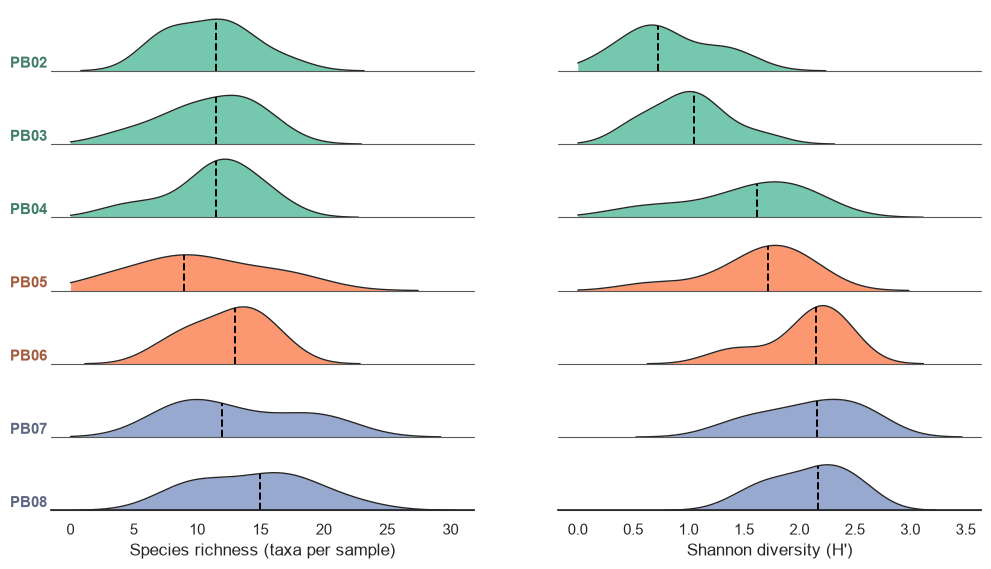

In [4]:
n_sites, n_met = len(site_order), len(METRICS)
fig, axes = plt.subplots(n_sites, n_met, figsize=FIG_SIZE, sharex="col", sharey="col", squeeze=False)

for j, (col, label) in enumerate(METRICS):
    for i, s in enumerate(site_order):
        ax = axes[i, j]
        draw_ridge(ax, df.loc[df[SITE_COL] == s, col], group_colors[site_group[s]])

    # Fix the shared y-range for this panel: zero baseline up to the tallest ridge
    ymax = max(ax.get_ylim()[1] for ax in axes[:, j])
    axes[0, j].set_ylim(0, ymax)
    axes[-1, j].set_xlabel(label)

# Hide y-axes (relative heights) and all spines except the x-axis on the bottom row
for ax in axes.ravel():
    ax.set_yticks([])
    ax.set_ylabel("")
sns.despine(fig=fig, left=True, bottom=True)
for j in range(n_met):
    sns.despine(ax=axes[-1, j], left=True, bottom=False)
    for i in range(n_sites - 1):
        axes[i, j].tick_params(bottom=False)

# Station labels at the left of the first column (just above each baseline), in a darkened version
# of the region colour: Set2's light fills are hard to read as text on a white background
for i, s in enumerate(site_order):
    label_color = tuple(0.65 * np.array(group_colors[site_group[s]]))
    axes[i, 0].text(-0.01, 0.0, s, transform=axes[i, 0].transAxes, ha="right", va="bottom",
                    color=label_color, fontweight="bold", fontsize=11)

## 4. Overlap the rows, add region separators and legend
A negative `hspace` pulls the rows together so ridges overlap. Each axes is as tall as the tallest ridge, and rows are one *row-spacing* apart, so `OVERLAP` = axes height / row spacing and `hspace = 1/OVERLAP - 1`. Later (lower) rows are drawn in front of earlier ones. Thin dashed horizontal lines (`SHOW_SEPARATORS`) mark the boundaries between regions; each sits a little above the baseline of the first station in the next region, so it passes behind that station's ridge. Two shared legends sit at the top, centred above both panels (they apply equally to both, and the panels themselves are full of ridges): the left one maps colour to bay region, the right one shows the dashed black line used for the station median. The median legend entry only appears if `SHOW_MEDIAN` is on.

In [5]:
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.10, top=0.88,
                    hspace=1 / OVERLAP - 1, wspace=0.06)

# Dashed separators between regions (figure-level lines placed behind the axes, which are transparent)
pitch = axes[0, 0].get_position().y0 - axes[1, 0].get_position().y0      # vertical distance between baselines
for i in range(1, n_sites if SHOW_SEPARATORS else 1):
    if site_group[site_order[i]] != site_group[site_order[i - 1]]:
        for j in range(n_met):
            pos = axes[i, j].get_position()
            y = pos.y0 + 0.35 * pitch
            fig.add_artist(Line2D([pos.x0, pos.x1], [y, y], transform=fig.transFigure,
                                  color="0.6", ls="--", lw=0.8, zorder=-1))

# Legend 1: colour -> bay region
region_handles = [Patch(facecolor=group_colors[g], alpha=0.9, label=g.title()) for g in GROUP_ORDER]
fig.legend(handles=region_handles, title="Bay region", loc="upper center",
           bbox_to_anchor=(0.32, 1.0), ncol=len(GROUP_ORDER), frameon=False)

# Legend 2: what the dashed black line means
if SHOW_MEDIAN:
    median_handle = Line2D([0], [0], color="black", ls="--", lw=1.4)
    fig.legend(handles=[median_handle], labels=["Station median"], title="Marker", loc="upper center",
               bbox_to_anchor=(0.72, 1.0), frameon=False)
plt.show()

## 5. Save
Writes a PNG (for slides and documents) and a PDF (vector, for journals or further editing) to `OUT_DIR`.

In [6]:
fig.savefig(OUT_DIR / "ridgeline_richness_shannon.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT_DIR / "ridgeline_richness_shannon.pdf", bbox_inches="tight")
print("Saved to", OUT_DIR.resolve())

Saved to /Users/Emily/Library/CloudStorage/Box-Box/Classes/OCS 7001 Scientific Computing (Fall 2026)/ridgeline_output
